# Thermal analysis of a fuel pin: PWR and SFR

**Exercises, 057922 Nuclear Design and Technology** · Politecnico di Milano

Author: Giovanni Zullo

Run the cells in order, or **Runtime > Run all**.

---

## Contents

1. The model
2. PWR, Seabrook
3. SFR, Superphénix
4. Exercises

## 1. The model

One coolant channel and its pin: the coolant by the enthalpy balance
along the height, then at every height the heat through four resistances in series, film,
cladding, gap and fuel.

- **PWR** (§2): a pin of the Seabrook PWR (Todreas and Kazimi, Vol. I, App. K,
  Tables K.1-K.2), water, a solid UO2 pellet with constant $k_f$.
- **SFR** (§3): an average pin of Superphénix (T&K Tables 1.2, 1.3, 2.1; Guidez and Prêle
  2017), sodium, an annular MOX pellet with $k(T)$.

In each case choose the axial shape of the linear power:
`SHAPE = "uniform"` or `SHAPE = "cosine"` (chopped cosine, extrapolated length $L_e$).
Both keep the same average $\bar q'$, hence the same power and the same coolant outlet.

Coolant, enthalpy balance on a slice, $\dot m c_p\,\mathrm{d}T_b = q'(z)\,\mathrm{d}z$, with $z$
from the mid-plane, $-L/2 \le z \le L/2$:

$$q'(z) = \bar q' \;\;\text{(uniform)}, \qquad q'(z) = q'_0 \cos\frac{\pi z}{L_e},\;\; q'_0 = F_z \bar q',\;\; F_z = \frac{\pi L/2L_e}{\sin(\pi L/2L_e)} \;\;\text{(chopped cosine)}$$

Radial, at each height, the same $q'(z)$ through four resistances:

| step | drop |
|---|---|
| film | $q'/(2\pi r_{co} h)$ |
| cladding | $(q'/2\pi k_c)\ln(r_{co}/r_{ci})$ |
| gap | $q'/(2\pi r_p h_{gap})$ |
| fuel | $\int_{T_s}^{T_{max}} k\,\mathrm{d}T = \dfrac{q'}{4\pi}F$, with $F = 1$ for a solid pellet and $F = F_{\mathrm{vOC}} = 1 - \dfrac{\ln\alpha^2}{\alpha^2 - 1}$, $\alpha = r_p/r_v$, for an annular one |

With a constant $k_f$ the fuel line is $T_{max} - T_s = (q'/4\pi k_f)\,F$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import brentq


def qprime(z, pin, shape):
    """Linear power at height z (m from the mid-plane), W/m."""
    L, Le, q = pin["L"], pin["Le"], pin["q_avg"]
    if shape == "uniform":
        return q * np.ones_like(z)
    Fz = (np.pi * L / (2 * Le)) / np.sin(np.pi * L / (2 * Le))
    return Fz * q * np.cos(np.pi * z / Le)


def coolant(z, pin, shape):
    """Bulk temperature T_b(z), C: the enthalpy balance integrated from the inlet."""
    L, Le, q, m, cp = pin["L"], pin["Le"], pin["q_avg"], pin["m"], pin["cp"]
    if shape == "uniform":
        return pin["T_in"] + q * (z + L / 2) / (m * cp)
    Fz = (np.pi * L / (2 * Le)) / np.sin(np.pi * L / (2 * Le))
    return pin["T_in"] + Fz * q * Le / (np.pi * m * cp) * (np.sin(np.pi * z / Le) + np.sin(np.pi * L / (2 * Le)))


def radial(q, Tb, pin):
    """Wall, inner cladding, pellet surface and fuel maximum at one height, C."""
    Tw = Tb + q / (2 * np.pi * pin["r_co"] * pin["h"])
    Tci = Tw + q / (2 * np.pi * pin["k_c"]) * np.log(pin["r_co"] / pin["r_ci"])
    Ts = Tci + q / (2 * np.pi * pin["r_p"] * pin["h_gap"])
    if pin["r_v"] > 0:
        a = pin["r_p"] / pin["r_v"]
        F = 1 - np.log(a**2) / (a**2 - 1)
    else:
        F = 1.0
    target = q / (4 * np.pi) * F                          # conductivity integral, W/m
    k = pin["k_f"]
    if callable(k):
        Tmax = brentq(lambda T: quad(k, Ts, T)[0] - target, Ts, 4000.0)
    else:
        Tmax = Ts + target / k
    return Tw, Tci, Ts, Tmax


def analyse(pin, shape, n=201):
    z = np.linspace(-pin["L"] / 2, pin["L"] / 2, n)
    q, Tb = qprime(z, pin, shape), coolant(z, pin, shape)
    T = np.array([radial(qi, tb, pin) for qi, tb in zip(q, Tb)])
    out = dict(z=z, q=q, Tb=Tb, Tw=T[:, 0], Tci=T[:, 1], Ts=T[:, 2], Tmax=T[:, 3])
    iw, ic = out["Tw"].argmax(), out["Tmax"].argmax()
    print(f"{pin['name']}, {shape} q': q'_max = {q.max()/1e3:.1f} kW/m, coolant {Tb[0]:.1f} -> {Tb[-1]:.1f} C"
          f" (dT = {Tb[-1]-Tb[0]:.1f} C)")
    print(f"  cladding surface max {out['Tw'][iw]:.1f} C at z = {z[iw]:+.2f} m;"
          f" fuel max {out['Tmax'][ic]:.0f} C at z = {z[ic]:+.2f} m")
    j = np.argmin(np.abs(z))                             # the mid-plane section
    print(f"  at the mid-plane: T_b {Tb[j]:.1f}, T_w {out['Tw'][j]:.1f}, T_ci {out['Tci'][j]:.1f},"
          f" T_s {out['Ts'][j]:.1f}, T_max {out['Tmax'][j]:.0f} C")
    return out


def plot(out, pin, shape):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.2), gridspec_kw=dict(width_ratios=[1, 1.4]))
    ax1.plot(out["q"] / 1e3, out["z"], color="#2a78d6")
    ax1.set_xlabel("linear power q' (kW/m)"); ax1.set_ylabel("height from the mid-plane z (m)")
    ax1.set_xlim(left=0); ax1.set_title(f"{pin['name']}: q'(z), {shape}")
    for key, lab, c in (("Tb", "coolant $T_b$", "#1baf7a"), ("Tw", "cladding surface $T_w$", "0.3"),
                        ("Ts", "pellet surface $T_s$", "#eb6834"), ("Tmax", "fuel maximum", "#2a78d6")):
        ax2.plot(out[key], out["z"], color=c, label=lab)
    ax2.set_xlabel("temperature (°C)"); ax2.legend(fontsize=8, frameon=False)
    ax2.set_title("temperatures along the pin")
    fig.tight_layout(); plt.show()

## 2. PWR, Seabrook

Data from T&K Vol. I, App. K: Table K.1 (geometry, power, flow) and Table K.2 (properties and
the constant $h$, $h_{gap}$, $k_c$, $k_f$ that T&K use for this plant). The flow per rod is the
effective core flow over the rods, $17\,476/50\,952$.

PWR (Seabrook), cosine q': q'_max = 28.1 kW/m, coolant 293.1 -> 326.3 C (dT = 33.2 C)
  cladding surface max 341.9 C at z = +0.62 m; fuel max 1602 C at z = +0.02 m
  at the mid-plane: T_b 309.7, T_w 337.3, T_ci 378.7, T_s 569.9, T_max 1602 C


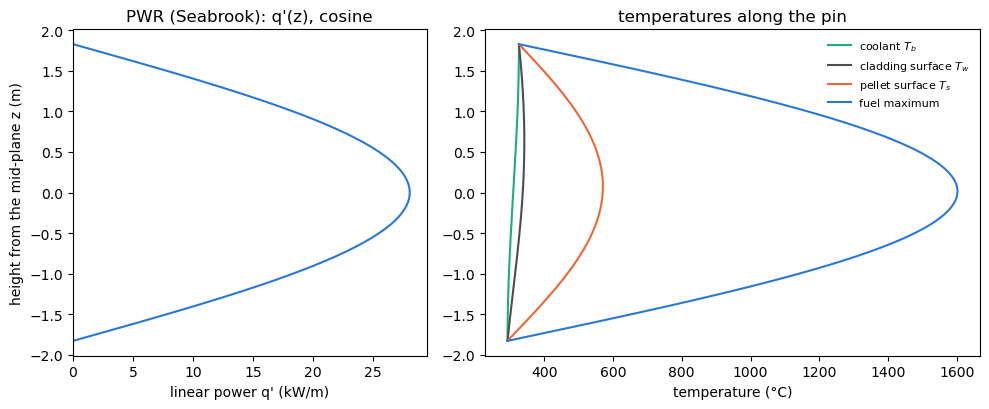

In [2]:
pwr = dict(
    name="PWR (Seabrook)",
    L=3.658, Le=3.658,              # heated length; L_e = L as in the notes (change to flatten)
    q_avg=17.86e3,                  # W/m, core average (T&K Table K.1)
    m=17476 / (193 * 264),          # kg/s per rod, effective flow over the rods
    cp=5742.0, T_in=293.1,          # J/(kg K) at T_avg (Table K.2), C (Table K.1)
    r_co=9.5e-3 / 2, r_ci=9.5e-3 / 2 - 0.572e-3, r_p=8.192e-3 / 2, r_v=0.0,
    h=34e3, h_gap=5.7e3,            # W/(m2 K), Table K.2
    k_c=13.85, k_f=2.163,           # W/(m K), Table K.2 (constant k_f)
)
SHAPE = "cosine"                    # "uniform" or "cosine"
res_pwr = analyse(pwr, SHAPE)
plot(res_pwr, pwr, SHAPE)

## 3. SFR, Superphénix

An average core pin: 29 kW/m over the 1.0 m fissile column (T&K Table 2.1), pin 8.5 mm with
0.56 mm of cladding (T&K Table 1.3), annular MOX pellet 7.14 mm with a 2 mm hole (Guidez and
Prêle, p. 4). The core produces $29 \times 1.0 \times 271 \times 364 = 2861$ MW of the 3000 MW of the plant,
the rest coming from the blankets, and the pin takes its share of the core flow in proportion
to power: $15\,700 \times (2861/3000)/(364 \times 271)$. Sodium at 470 °C (T&K Table E.8).

- film: Mikityuk's correlation for liquid metals in triangular bundles (T&K eq. 10.133);
- gap: open, as at the first rise to power, $h_{gap} \approx 3000$ W/(m² K) from the helium
  conductivity (T&K eqs. 8.138, 8.140);
- fuel: $k(T)$ of (U,Pu)O2 at 95 % TD, Waltar et al. (2012), eq. 9.6;
- axial: the 0.3 m axial blankets above and below keep the flux up at the ends, $L_e = 1.6$ m
  (an assumption: it treats the blankets as a reflector).

Re = 92161, Pr = 0.0048, Pe = 439, P/D = 1.153: Nu = 7.42, h = 123216 W/(m2 K)
SFR (Superphenix), cosine q': q'_max = 34.2 kW/m, coolant 395.0 -> 545.5 C (dT = 150.5 C)
  cladding surface max 551.3 C at z = +0.50 m; fuel max 1927 C at z = +0.04 m
  at the mid-plane: T_b 470.2, T_w 480.6, T_ci 514.1, T_s 1023.0, T_max 1923 C


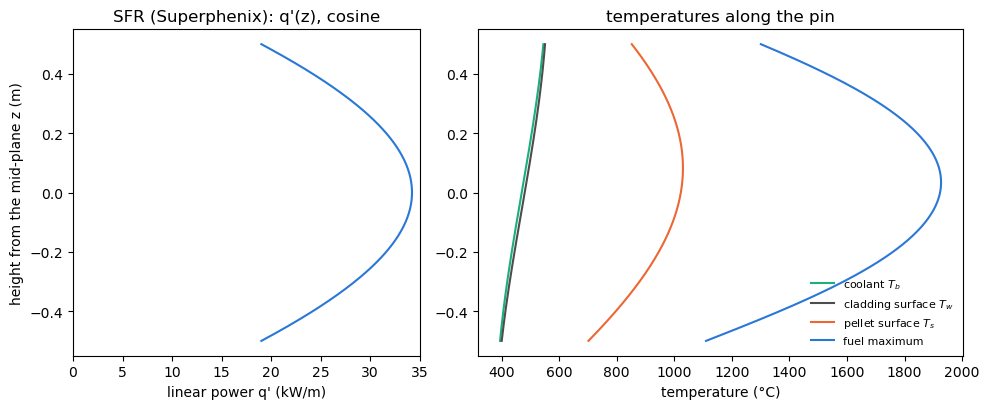

In [3]:
# sodium film, Mikityuk on the unit cell of the triangular lattice
d, p_, rho, cp_na, eta, k_na = 8.5e-3, 9.8e-3, 772.3, 1269.7, 2.467e-4, 65.7
m_sfr = 15700 * 2861 / 3000 / (364 * 271)
A_cell = np.sqrt(3) / 2 * p_**2 - np.pi * d**2 / 4
De = 4 * A_cell / (np.pi * d)
Re = m_sfr / A_cell * De / eta; Pr = cp_na * eta / k_na; Pe = Re * Pr; PD = p_ / d
Nu = 0.047 * (1 - np.exp(-3.8 * (PD - 1))) * (Pe**0.77 + 250)
h_na = Nu * k_na / De
print(f"Re = {Re:.0f}, Pr = {Pr:.4f}, Pe = {Pe:.0f}, P/D = {PD:.3f}: Nu = {Nu:.2f}, h = {h_na:.0f} W/(m2 K)")

k_mox = lambda T: 1 / (0.042 + 2.71e-4 * (T + 273.15)) + 6.9e-11 * (T + 273.15)**3   # W/(m K), T in C

sfr = dict(
    name="SFR (Superphenix)",
    L=1.0, Le=1.6,                  # heated length = fissile column; L_e with the axial blankets
    q_avg=29e3,                     # W/m (T&K Table 2.1)
    m=m_sfr, cp=cp_na, T_in=395.0,
    r_co=d / 2, r_ci=d / 2 - 0.56e-3, r_p=7.14e-3 / 2, r_v=2.0e-3 / 2,
    h=h_na, h_gap=3.0e3,            # W/(m2 K); open gap, first rise to power
    k_c=23.0, k_f=k_mox,            # type 316; MOX k(T)
)
SHAPE = "cosine"                    # "uniform" or "cosine"
res_sfr = analyse(sfr, SHAPE)
plot(res_sfr, sfr, SHAPE)

## 4. Exercises

1. Switch `SHAPE` between `"uniform"` and `"cosine"` in both cases. Where is the hottest point of
   the cladding, and of the fuel? Why does the coolant outlet not change?
2. In the PWR cell set `Le` to 1.2 L, then to 2 L. What happens to $F_z$, to $q'_0$ and to the
   fuel maximum?
3. Compare the four drops at the mid-plane in the two reactors. Which resistance carries most of
   the rise in each, and why is the sodium film so small?
4. In the SFR cell close the gap, `h_gap = 10e3`. How much does the fuel maximum drop?
5. In the PWR cell replace the constants of T&K Table K.2 with $k_f = 3$, $k_c = 17$ W/(m K),
   $h_{gap} = 5000$ and $h = 48\,300$ W/(m² K). Which change moves the fuel maximum most, and
   why that one?